In [1]:
import json 
import os 
import math

import torch
import torch.nn as nn

import numpy as np
import matplotlib.pyplot as plt
import tiktoken

from importlib.metadata import version

In [2]:
GPT_CONFIG = {
    "vocab_size": 50257,
    "context_length": 256,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False,
}

In [3]:
import json
import os

def import_from_ipynb(nb_path, *names):
    """Execute notebook code cells that define classes/functions/configs, skipping test runs."""
    candidates = [
        nb_path,
        os.path.join(os.path.dirname(__file__) if '__file__' in locals() else '.', nb_path),
        os.path.abspath(f"src/buildinglargelanguagemodel/LLM/{nb_path}"),
        f"/home/lakshay/BuildingLargeLanguageModel/src/buildinglargelanguagemodel/LLM/{nb_path}"
    ]
    resolved_path = next((p for p in candidates if os.path.exists(p)), None)
    if not resolved_path:
        raise FileNotFoundError(f"Could not find {nb_path}.")

    with open(resolved_path, "r", encoding="utf-8") as f:
        nb_data = json.load(f)

    skip_signatures = [
        "logits = model(batch)",
        "start_context =",
        "layer_sizes =",
        "batch = torch.tensor",
        "out_ffn = ffn(",
        "out_att = att(",
        "out_block = block(",
        "ln_out = ln(",
        "y_gelu = gelu(x)",
        "total_params = sum("
    ]

    code_blocks = []
    for cell in nb_data.get("cells", []):
        if cell.get("cell_type") == "code":
            src = "".join(cell.get("source", []))
            if any(sig in src for sig in skip_signatures):
                continue
            code_blocks.append(src)

    exec_scope = {}
    exec("\n\n".join(code_blocks), exec_scope)
    return [exec_scope[name] for name in names]

GPTModel, generate_text_simple = import_from_ipynb("llm_architecture.ipynb", "GPTModel", "generate_text_simple")

Successfully imported CausalMultiHeadSelfAttention from: /home/lakshay/BuildingLargeLanguageModel/src/buildinglargelanguagemodel/Attention/multihead_self_attention.ipynb


In [4]:
torch.manual_seed(123)

model = GPTModel(GPT_CONFIG)
model.eval()

print("Model initialized successfully!")
print("Total parameters:", sum(p.numel() for p in model.parameters()))

Model initialized successfully!
Total parameters: 162419712


In [5]:
def generate_text_simple(model, idx, max_new_tokens, context_size):
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]

        with torch.no_grad():
            logits = model(idx_cond)

        logits = logits[:, -1, :]
        probas = torch.softmax(logits, dim=-1)
        idx_next = torch.argmax(probas, dim=-1, keepdim=True)

        idx = torch.cat((idx, idx_next), dim=1)

    return idx

In [6]:
def text_to_token_ids(text, tokenizer):

    encoded = tokenizer.encode(text, allowed_special = {"<|endoftext|>"})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0)

    return encoded_tensor 

In [7]:
start_context = "non of the above"

tokenizer = tiktoken.get_encoding("gpt2")

token_ids = text_to_token_ids(start_context, tokenizer)
token_ids 

tensor([[13159,   286,   262,  2029]])

In [8]:
def token_ids_to_text(token_ids , tokenizer):

    flat = token_ids.squeeze(0)

    return tokenizer.decode(flat.tolist())

token_ids_to_text(token_ids, tokenizer)

'non of the above'

In [9]:
token_ids = generate_text_simple(

    model = model,
    idx = text_to_token_ids(start_context, tokenizer),
    max_new_tokens = 10,
    context_size = GPT_CONFIG["context_length"]
)

In [10]:
token_ids.squeeze_(0)

tensor([13159,   286,   262,  2029, 24075,  7901, 48218, 13772, 29924, 35075,
        39357, 17297, 13981, 10274])

In [11]:
token_ids_to_text(token_ids, tokenizer)

'non of the above Wisdom commitment Bridgewater blamed repo juicy698 Jin MLS Ban'

In [12]:
# log_probs = torch.log(torch.cat((target_probas_1 , target_probas_2)))
# -1*torch.mean(log_probs)
# print(log_probs)

In [13]:
# Load and truncate TinyStories dataset to ~3 Million tokens cleanly at story boundary
file_path = "/home/lakshay/BuildingLargeLanguageModel/src/buildinglargelanguagemodel/data/train.txt"

with open(file_path, "r", encoding="utf-8") as file:
    raw_text = file.read()

TARGET_TOKENS = 3_000_000
# Find clean story boundary (\n\n) near 3M tokens (~11.98 MB of text)
approx_chars = int(TARGET_TOKENS * 3.993)
cut_boundary = raw_text.find("\n\n", approx_chars)
content = raw_text[:cut_boundary] if cut_boundary != -1 else raw_text[:approx_chars]

print(f"Loaded truncated corpus: {len(content) / (1024**2):.2f} MB")
print(f"Preview (first 100 chars):\n{content[:100]}...")


Loaded truncated corpus: 11.42 MB
Preview (first 100 chars):
One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with...


In [14]:
total_character = len(content)
total_token = len(tokenizer.encode(content))

print(f"Characters: {total_character:,}")
print(f"Tokens    : {total_token:,}")


Characters: 11,979,063
Tokens    : 3,000,308


In [15]:
import torch
from torch.utils.data import Dataset, DataLoader

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        token_ids = tokenizer.encode(txt,allowed_special={"<|endoftext|>"})            
            
        for i in range(0, len(token_ids) - max_length, stride):

            input_chunk = token_ids[i : i + max_length]

            target_chunk = token_ids[i + 1 : i + max_length + 1]

            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)
    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

In [16]:
def create_dataloader_v1(txt, batch_size = 4, max_length = 256, stride = 128, shuffle = True, drop_last = True, num_workers = 0):

    tokenizer = tiktoken.get_encoding("gpt2")

    dataset = GPTDatasetV1(txt , tokenizer ,max_length, stride)

    dataloader = DataLoader(
        dataset,
        batch_size = batch_size,
        shuffle = shuffle,
        drop_last = drop_last,
        num_workers = num_workers,
    )

    return dataloader

In [17]:
train_ratio = 0.90
split_idx = int(train_ratio * len(content))
train_data = content[:split_idx]
val_data = content[split_idx:]

In [18]:
torch.manual_seed(123)

train_loader = create_dataloader_v1(
    train_data,
    batch_size = 2,
    max_length = GPT_CONFIG['context_length'],
    stride = GPT_CONFIG['context_length'],
    drop_last = True,
    shuffle = True,
    num_workers = 0
)


val_loader = create_dataloader_v1(
    val_data,
    batch_size = 2,
    max_length = GPT_CONFIG['context_length'],
    stride = GPT_CONFIG['context_length'],
    drop_last = False,
    shuffle = False,
    num_workers = 0
)

In [19]:
print("Train data preview (first 3 batches):")
for i, (x, y) in enumerate(train_loader):
    if i >= 3:
        break
    print(f"Batch {i}: inputs {x.shape}, targets {y.shape}")


Train data preview (first 3 batches):
Batch 0: inputs torch.Size([2, 256]), targets torch.Size([2, 256])
Batch 1: inputs torch.Size([2, 256]), targets torch.Size([2, 256])
Batch 2: inputs torch.Size([2, 256]), targets torch.Size([2, 256])


In [20]:
print("Val data preview (first 3 batches):")
for i, (x, y) in enumerate(val_loader):
    if i >= 3:
        break
    print(f"Batch {i}: inputs {x.shape}, targets {y.shape}")


Val data preview (first 3 batches):
Batch 0: inputs torch.Size([2, 256]), targets torch.Size([2, 256])
Batch 1: inputs torch.Size([2, 256]), targets torch.Size([2, 256])
Batch 2: inputs torch.Size([2, 256]), targets torch.Size([2, 256])


In [21]:
# Compute exact token counts in train and val sets
train_tokens = len(train_loader) * train_loader.batch_size * GPT_CONFIG["context_length"]
val_tokens = len(val_loader) * val_loader.batch_size * GPT_CONFIG["context_length"]

print(f"Train Tokens     : {train_tokens:,} ({len(train_loader):,} batches)")
print(f"Validation tokens: {val_tokens:,} ({len(val_loader):,} batches)")
print(f"Total tokens     : {train_tokens + val_tokens:,}")


Train Tokens     : 2,694,656 (5,263 batches)
Validation tokens: 305,664 (597 batches)
Total tokens     : 3,000,320


In [22]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device 

device(type='cuda')

In [23]:
def calc_loss_batch(input_batch, target_batch, model, device):

    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = model(input_batch)

    loss = torch.nn.functional.cross_entropy(logits.flatten(0, 1), target_batch.flatten())
    return loss


def calc_loss_loader(data_loader, model, device, num_batches=None):

    total_loss = 0.

    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches, len(data_loader))

    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break
        
    return total_loss / num_batches

In [ ]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Using {device} device.")
model.to(device)

torch.manual_seed(123)
with torch.no_grad(): 
    train_loss = calc_loss_loader(train_loader, model, device, num_batches=10)
    val_loss = calc_loss_loader(val_loader, model, device, num_batches=10)

print(f"Initial Training loss  : {train_loss:.3f}")
print(f"Initial Validation loss: {val_loss:.3f}")


Using cuda device.
Initial Training loss  : 10.937
Initial Validation loss: 10.939


In [25]:
def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs,
                       eval_freq, eval_iter, start_context, tokenizer):
    
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, -1


    for epoch in range(num_epochs):
        model.train()  
        
        for input_batch, target_batch in train_loader:
            optimizer.zero_grad() 
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward() 
            optimizer.step() 
            tokens_seen += input_batch.numel()
            global_step += 1

            
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")

       
        generate_and_print_sample(
            model, tokenizer, device, start_context
        )

    return train_losses, val_losses, track_tokens_seen


def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss, val_loss


def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded = text_to_token_ids(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate_text_simple(
            model=model, idx=encoded,
            max_new_tokens=50, context_size=context_size
        )
    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))  # Compact print format
    model.train()


In [26]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG)
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004, weight_decay=0.1)

num_epochs = 1
train_losses, val_losses, tokens_seen = train_model_simple(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    device=device,
    num_epochs=num_epochs,
    eval_freq=100,
    eval_iter=5,
    start_context="Every effort moves you",
    tokenizer=tokenizer
)


Ep 1 (Step 000000): Train loss 9.699, Val loss 9.894
Ep 1 (Step 000100): Train loss 4.830, Val loss 5.111
Ep 1 (Step 000200): Train loss 4.796, Val loss 4.610
Ep 1 (Step 000300): Train loss 4.426, Val loss 4.487
Ep 1 (Step 000400): Train loss 4.176, Val loss 4.313
Ep 1 (Step 000500): Train loss 4.181, Val loss 4.224
Ep 1 (Step 000600): Train loss 4.017, Val loss 4.135
Ep 1 (Step 000700): Train loss 4.090, Val loss 4.094
Ep 1 (Step 000800): Train loss 3.779, Val loss 4.031
Ep 1 (Step 000900): Train loss 3.859, Val loss 3.972
Ep 1 (Step 001000): Train loss 4.092, Val loss 3.959
Ep 1 (Step 001100): Train loss 3.846, Val loss 3.907
Ep 1 (Step 001200): Train loss 3.785, Val loss 3.879
Ep 1 (Step 001300): Train loss 4.006, Val loss 3.852
Ep 1 (Step 001400): Train loss 4.217, Val loss 3.837
Ep 1 (Step 001500): Train loss 3.732, Val loss 3.820
Ep 1 (Step 001600): Train loss 4.024, Val loss 3.833
Ep 1 (Step 001700): Train loss 3.823, Val loss 3.865
Ep 1 (Step 001800): Train loss 3.703, Val loss

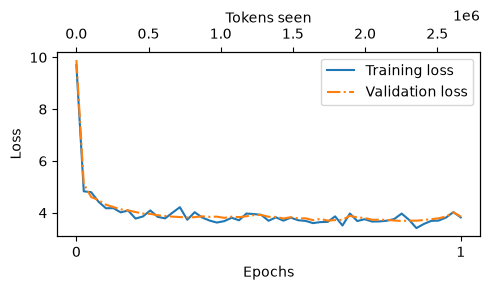

In [27]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5, 3))

    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))  
    ax2 = ax1.twiny()  
    ax2.plot(tokens_seen, train_losses, alpha=0)  
    ax2.set_xlabel("Tokens seen")

    fig.tight_layout()  
    plt.savefig("loss-plot.pdf")
    plt.show()

epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

In [29]:
inference_device = torch.device("cpu")

model.to(inference_device)
model.eval()

tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer).to(inference_device),
    max_new_tokens=25,
    context_size=GPT_CONFIG["context_length"]
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))


Output text:
 Every effort moves you can play.
The boy and said, "I'm you want to play with you, you can the box you want


In [30]:
vocab = { 
    "closer": 0,
    "every": 1, 
    "effort": 2, 
    "forward": 3,
    "inches": 4,
    "moves": 5, 
    "pizza": 6,
    "toward": 7,
    "you": 8,
} 

inverse_vocab = {v: k for k, v in vocab.items()}

next_token_logits = torch.tensor(
    [4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)

probas = torch.softmax(next_token_logits, dim=0)
next_token_id = torch.argmax(probas).item()

print(inverse_vocab[next_token_id])

forward


In [ ]:


def print_sampled_tokens(probas):
    torch.manual_seed(123) 
    sample = [torch.multinomial(probas, num_samples=1).item() for i in range(1_000)]
    sampled_ids = torch.bincount(torch.tensor(sample), minlength=len(probas))
    for i, freq in enumerate(sampled_ids):
        print(f"{freq} x {inverse_vocab[i]}")

print_sampled_tokens(probas)



73 x closer
0 x every
0 x effort
582 x forward
2 x inches
0 x moves
0 x pizza
343 x toward
0 x you


In [32]:


def softmax_with_temperature(logits, temperature):
    scaled_logits = logits / temperature
    return torch.softmax(scaled_logits, dim=0)

# Temperature values
temperatures = [1, 0.1, 5]  # Original, higher confidence, and lower confidence

# Calculate scaled probabilities
scaled_probas = [softmax_with_temperature(next_token_logits, T) for T in temperatures]



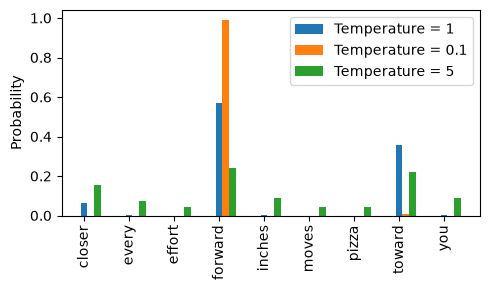

In [33]:


# Plotting
x = torch.arange(len(vocab))
bar_width = 0.15

fig, ax = plt.subplots(figsize=(5, 3))
for i, T in enumerate(temperatures):
    rects = ax.bar(x + i * bar_width, scaled_probas[i], bar_width, label=f'Temperature = {T}')

ax.set_ylabel('Probability')
ax.set_xticks(x)
ax.set_xticklabels(vocab.keys(), rotation=90)
ax.legend()

plt.tight_layout()
plt.savefig("temperature-plot.pdf")
plt.show()



In [38]:
def generate(model, idx, max_new_tokens, context_size, temperature=0.0, top_k=None, eos_id=None):

    # For-loop is the same as before: Get logits, and only focus on last time step
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :]

        # New: Filter logits with top_k sampling
        if top_k is not None:
            # Keep only top_k values
            top_logits, _ = torch.topk(logits, top_k)
            min_val = top_logits[:, -1]
            logits = torch.where(logits < min_val, torch.tensor(float("-inf")).to(logits.device), logits)

        # New: Apply temperature scaling
        if temperature > 0.0:
            logits = logits / temperature

            # New (not in book): numerical stability tip to get equivalent results on mps device
            # subtract rowwise max before softmax
            logits = logits - logits.max(dim=-1, keepdim=True).values
            
            # Apply softmax to get probabilities
            probs = torch.softmax(logits, dim=-1)  # (batch_size, vocab_size)

            # Sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1)  # (batch_size, 1)

        # Otherwise same as before: get idx of the vocab entry with the highest logits value
        else:
            idx_next = torch.argmax(logits, dim=-1, keepdim=True)  # (batch_size, 1)

        if idx_next == eos_id:  # Stop generating early if end-of-sequence token is encountered and eos_id is specified
            break

        # Same as before: append sampled index to the running sequence
        idx = torch.cat((idx, idx_next), dim=1)  # (batch_size, num_tokens+1)

    return idx


In [39]:
torch.manual_seed(123)

token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer).to(inference_device),
    max_new_tokens=15,
    context_size=GPT_CONFIG["context_length"],
    top_k=25,
    temperature=1.4
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you ErrorARDIS� Lana Mock wholesalespot traditional historyWowliness landfall Germans arrange odor


In [40]:
# Save the trained model weights
torch.save(model.state_dict(), "model.pth")
print("Model weights saved successfully to model.pth!")


Model weights saved successfully to model.pth!


In [41]:


model = GPTModel(GPT_CONFIG)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    # Use PyTorch 2.9 or newer for stable mps results
    major, minor = map(int, torch.__version__.split(".")[:2])
    if (major, minor) >= (2, 9):
        device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Device:", device)

model.load_state_dict(torch.load("model.pth", map_location=device, weights_only=True))
model.eval();



Device: cuda


In [42]:
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    }, 
    "model_and_optimizer.pth"
)


In [43]:
checkpoint = torch.load("model_and_optimizer.pth", weights_only=True)

model = GPTModel(GPT_CONFIG)
model.load_state_dict(checkpoint["model_state_dict"])

optimizer = torch.optim.AdamW(model.parameters(), lr=0.0005, weight_decay=0.1)
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
model.train();